In [1]:
cd ..

c:\Users\tangr\GitHub\pc-centrelines


In [2]:
conduit_map = {
    1:"straight_cyl",
    2:"straight_elp",
    3: "wavy",
    4:"rough",
    5:"sinu_1",
    6:"sinu_2",
    7:"branching",
    8:"archamps",
    9:"motiers",
    10:"faux_monnayeurs"
    }


## Data preparation

In [3]:
import yaml
import numpy as np
from base.frechet_dist import frdist
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [4]:
# a convenience function to resample a centreline using a 1d interpolator. 
def parametrise_ct(ct, eps):
    t = np.zeros(ct.shape[0])

    segments = np.linalg.norm(np.diff(ct, axis = 0), axis = 1)
    
    cumsum = np.cumsum(segments)

    L = np.max(cumsum)
    t[1:] =  cumsum / L

    x_interp  = interp1d(t, ct[:,  0])
    y_interp  = interp1d(t, ct[:,  1])
    if ct.shape[1] == 3:
        z_interp  = interp1d(t, ct[:,  2])

    # now we work out the reparametrisation so that the average segment length is close to the required delta.
    ti = []
    t0 = 0
    for segment in segments:
        r = np.ceil(segment/eps)
        increments =  [t0+ i * segment / r for i in np.arange(0, r)]
        for increment in increments:
            ti.append(increment / L)
        t0 +=segment
    
    ti.append(1)
        
    if ct.shape[1] == 3:
        return np.vstack([x_interp(ti), y_interp(ti), z_interp(ti)]).T
    else:
        return np.vstack([x_interp(ti), y_interp(ti)]).T


In [5]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [6]:
# list all lbc centrelines, the sources and the target points
list_lbc_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    lbc_ct_fp = f"./temp/{conduit_id}_{conduit_name}/lbc/{conduit_name}_centreline.txt"

    lbc_ct = np.loadtxt(lbc_ct_fp)
    P1 = lbc_ct[0]
    P2 = lbc_ct[-1]

    list_lbc_ct.append((lbc_ct, P1, P2))

In [7]:
# list all voxelised centrelines, the sources and the target points
list_mst_ct = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    if k < 7:
        delta = 200
    else: 
        delta = 400
    
    mst_ct_fp = f"./temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-simplified.txt"
    
    try: 
        mst_ct = np.loadtxt(mst_ct_fp)
    except FileNotFoundError:
        mst_ct = np.loadtxt(f"./temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-direct.txt")
    P1 = mst_ct[0]
    P2 = mst_ct[-1]

    list_mst_ct.append((mst_ct, P1, P2))

In [8]:
# list all iterative centrelines, the sources and the target points
list_iter_ct = []
list_iter_norm = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    iter_ct_fp = f"./temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_centreline.txt"
    iter_norm_fp = f"./temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_vectors.txt"

    iter_ct = np.loadtxt(iter_ct_fp)
    iter_norm = np.loadtxt(iter_norm_fp)
    print(np.mean(iter_ct, axis = 0)) 
    P1 = iter_ct[0]
    P2 = iter_ct[-1]

    list_iter_ct.append((iter_ct, P1, P2))
    list_iter_norm.append(iter_norm)

[-1.05062572e-01  9.81152589e-05  1.37409231e-04]
[-1.06589522e-01  2.39166368e-04  8.27264029e-05]
[ 0.00551136 -0.00030335  0.00060712]
[-0.12904862 -0.02858769 -0.03483494]
[0.01606131 0.01713299 0.00169107]
[-4.42635527e+00  2.01393364e+00 -1.96948762e-03]
[0.0363256  0.01212195 0.00609678]
[-0.06430868  0.22111751 -1.00721533]
[ 0.80790049 -0.63976681 -0.39329461]
[ 0.34112024 -0.03008052 -1.64151216]


In [9]:
# list hydraulic centrelines, sources and target points. 
## plot the hydraulic centrelines. 
list_hydraulic_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    hydraulic_ct_fp = f"./temp/{conduit_id}_{conduit_name}/hydraulic/{conduit_name}_centreline.csv"
    
    if k < 7:
        hydraulic_ct1 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[1,2,3])
        hydraulic_ct2 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[4,5,6])

        P1 = hydraulic_ct1[0]
        P2 = hydraulic_ct1[-1]

        list_hydraulic_ct.append((hydraulic_ct1, P1, P2, hydraulic_ct2))

## plotting args. 

In [10]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [11]:
conduit_map

{1: 'straight_cyl',
 2: 'straight_elp',
 3: 'wavy',
 4: 'rough',
 5: 'sinu_1',
 6: 'sinu_2',
 7: 'branching',
 8: 'archamps',
 9: 'motiers',
 10: 'faux_monnayeurs'}

## measure the extremities distances...

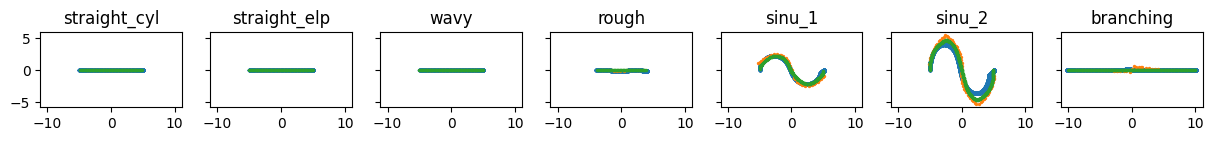

In [12]:
fig, axes = plt.subplots(1,7, figsize = (15, 3), sharey=True, sharex=True)

for k, ax in enumerate(axes):
    ax.scatter(*list_hydraulic_ct[k][0][:, [0, 1]].T, s = 2)
    ax.scatter(*list_lbc_ct[k][0][:, [0, 1]].T, s = 2)
    ax.scatter(*list_mst_ct[k][0][:, [0, 1]].T, s = 2)
    #ax.scatter(*list_iter_ct[k][0][:, [0, 1]].T, s = 2)
    ax.set_title(conduit_map[k+1])
    ax.set_aspect("equal")
plt.show()

In [20]:
print("LBC extremities")
LBC_extremities = []
for k in range(0, 7):
    P1_hyd, P2_hyd =  list_hydraulic_ct[k][1], list_hydraulic_ct[k][2]
    P1_lbc, P2_lbc  =  list_lbc_ct[k][1], list_lbc_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_hyd-P1_lbc), np.linalg.norm(P2_hyd-P1_lbc))
    which = np.argmin((np.linalg.norm(P1_hyd-P1_lbc), np.linalg.norm(P2_hyd-P1_lbc)))
    dist2 = [np.linalg.norm(P2_hyd-P2_lbc), np.linalg.norm(P1_hyd-P2_lbc)][which]
    LBC_extremities.append([dist1,dist2])
    print(k+1, [dist1, dist2])
LBC_extremities = np.array(LBC_extremities)
print("MST extremities")
MST_extremities = []

for k in range(0, 7):
    P1_mst, P2_mst  =  list_mst_ct[k][1], list_mst_ct[k][2]
    P1_hyd, P2_hyd =  list_hydraulic_ct[k][1], list_hydraulic_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_hyd-P1_mst), np.linalg.norm(P2_hyd-P1_mst))
    which = np.argmin((np.linalg.norm(P1_hyd-P1_mst), np.linalg.norm(P2_hyd-P1_mst)))
    dist2 = [np.linalg.norm(P2_hyd-P2_mst), np.linalg.norm(P1_hyd-P2_mst)][which]
    MST_extremities.append([dist1,dist2])

    print(k+1, [dist1, dist2])
MST_extremities = np.array(MST_extremities)
print("Iterative extremities")
iter_extremities = []

for k in range(0, 7):
    P1_iter, P2_iter  =  list_iter_ct[k][1], list_iter_ct[k][2]
    P1_hyd, P2_hyd =  list_hydraulic_ct[k][1], list_hydraulic_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_hyd-P1_iter), np.linalg.norm(P2_hyd-P1_iter))
    which = np.argmin((np.linalg.norm(P1_hyd-P1_iter), np.linalg.norm(P2_hyd-P1_iter)))
    dist2 = [np.linalg.norm(P2_hyd-P2_iter), np.linalg.norm(P1_hyd-P2_iter)][which]
    iter_extremities.append([dist1,dist2])

    print(k+1, [dist1, dist2])

iter_extremities = np.array(iter_extremities)

LBC extremities
1 [1.2122317033164063, 1.1863784769533867]
2 [1.0441182636084172, 1.0433837119208258]
3 [1.124593988328509, 1.1253169867283934]
4 [0.9575726453167549, 1.211411655843856]
5 [1.107412161315043, 0.9799949194989294]
6 [0.9969096795537079, 0.9792738117361357]
7 [1.3723049203812532, 1.3285905837880303]
MST extremities
1 [0.18999614533862755, 0.18085025405699073]
2 [0.044461535455947186, 0.014689539930157789]
3 [0.013882902957126499, 0.008700656831969652]
4 [0.19011688782009284, 0.23624674366272244]
5 [0.18391812953880757, 0.237397174409644]
6 [0.023362483351392883, 0.02732192980967827]
7 [0.1197250573338484, 0.11241163661930377]
Iterative extremities
1 [0.08614621677097614, 0.1156276265021026]
2 [0.058886151095778744, 0.12684635903513275]
3 [0.014010997568489312, 0.016548204255499237]
4 [0.13567170903137077, 0.13925189834369114]
5 [0.15344944571302951, 0.17535223000211184]
6 [0.09939106077755513, 8.038112276119744]
7 [0.23015963669685185, 0.180979326749984]


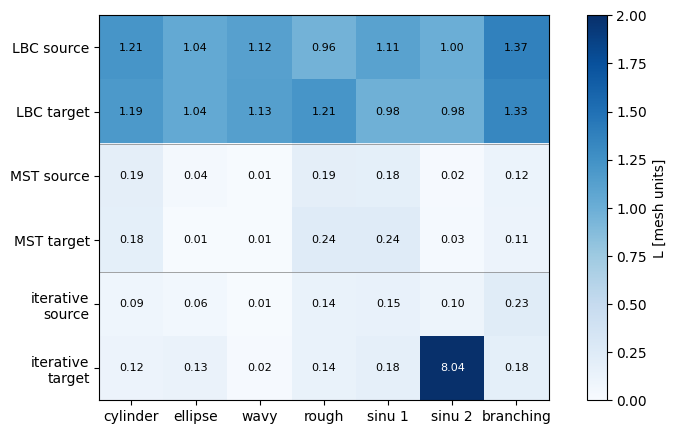

In [ ]:
fig, ax = plt.subplots(figsize = (10, 5))

extremities_distance = np.vstack([LBC_extremities.T, MST_extremities.T, iter_extremities.T])
im = ax.imshow(extremities_distance, cmap = "Blues", vmin = 0, vmax=2)
xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "branching"]
ylabels = ["LBC source", "LBC target", "MST source", "MST target", "iterative\nsource", "iterative\ntarget",]


ax.set_xticks([0,1,2,3,4,5,6])
ax.set_xticklabels(xlabels)
ax.set_yticks([0,1,2,3,4,5])
ax.set_yticklabels(ylabels)


for j, row in enumerate(extremities_distance):
    for i, elem in enumerate(row):
        color = "k"
        if elem > 4:
            color = "white"
        if elem > 0:

            ax.text(i,j, f"{elem:.2f}", fontsize = 8, va = "center", ha="center", color =color)

ax.set_aspect("equal")
ax.axhline(3.5, color = "grey", lw = 0.5)
ax.axhline(1.5, color = "grey", lw = 0.5)
ax.set_ylim(5.5, -0.5)
cax = plt.colorbar(im)
cax.set_label("L [mesh units]")
plt.tight_layout()
plt.savefig("../temp/figures/distance_to_extremities.png", dpi = 300)


## Fréchet pitfalls. Flip, Clip, Parametrise.

When calculating the discrete Frechet metric, we try to find the infemum of any coupling between two nodes of a polyline. Ideally, all our centrelines would begin at the same start point and finish at the same end point. But it is not the case for the hydraulic lines. The discrete frechet metric would be dominated by this discrepancy. 

Another thing to bear in mind is the order of parametrisation of our polylines.

In [ ]:
fig, ax = plt.subplots()

# hydraulic centreline 1
# lbc centreline 1. 
hyd_ct1 = list_hydraulic_ct[0][0]
lbc_ct1 = list_lbc_ct[0][0]

ax.plot(*lbc_ct1[:, [0,1]].T, "-o")
ax.plot(*hyd_ct1[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1[-1, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Here the start and end of our lines are reversed, so the discrete frechet metric is quite large. 
We would have to take the minimum of the two. Also, we have to be careful of the recursion depth in checking the coupling distances. 
The hydraulic centreline is very densely sampled, perhaps too densely. We could resample it to a step of 0.1 and calculate the frechet metric then. 

In [ ]:
parametrise_ct(hyd_ct1, 2)

In [ ]:
# naive calculation using near identical lines, but parametrised in opposite directions, under
# condition of monotonic increasing parametrisation.
frdist(parametrise_ct(hyd_ct1[::50], 2), lbc_ct1)

In [ ]:
fig, ax = plt.subplots()

# hydraulic centreline 1
# lbc centreline 1. 
hyd_ct1 = list_hydraulic_ct[0][0]
lbc_ct1 = list_lbc_ct[0][0]

ax.plot(*lbc_ct1[:, [0,1]].T, "-o")
ax.plot(*parametrise_ct(hyd_ct1[::50], 0.1)[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1[-1, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1[0, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Intuitively in this example, the discrete frechet distance metric between these two parallel lines should be near equal to the maximum of the distance between the start points or end points.

In [ ]:
frdist(parametrise_ct(hyd_ct1[::50], 0.1), lbc_ct1[::-1])

We can check this is the case: 

In [ ]:
print("distance between start points: ", np.linalg.norm(lbc_ct1[-1] - hyd_ct1[0]))
print("distance between end points: ", np.linalg.norm(lbc_ct1[0] - hyd_ct1[-1]))

Trimming: we may have to use the best of both worlds... 

In [ ]:
def trim_adjust(ct1, ct2, eps):
    # we essentially reparametrise the lines to begin as close as possible. 

    ct1_ct2_nearest = np.argmin(np.linalg.norm(ct1[0] - ct2[[0, -1], :], axis =1))
    # this is only zero, or one. 
    flip = 1
    if ct1_ct2_nearest ==1:
        flip = -1

    ct1_parametrised = parametrise_ct(ct1, eps)
    ct2_parametrised = parametrise_ct(ct2[::flip], eps)

    # check whether a point in ct1 is closer to ct2_0. if so, we have to trim until there.
    idx_ct1_1 = np.argmin(np.linalg.norm(ct2[::flip][0] - ct1_parametrised,  axis=1))
    idx_ct2_1 = np.argmin(np.linalg.norm(ct1[0] - ct2_parametrised,  axis=1))

    idx_ct1_2 = np.argmin(np.linalg.norm(ct2[::flip][-1] - ct1_parametrised,  axis=1))
    idx_ct2_2 = np.argmin(np.linalg.norm(ct1[-1] - ct2_parametrised,  axis=1))

    P = ct1_parametrised[idx_ct1_1:idx_ct1_2]
    Q = ct2_parametrised[idx_ct2_1:idx_ct2_2]


    # projection of a point on a segment.
    # si qprime - Q[1] @ qprim - Q[0] = -1, alors, bon, Q[0] = qprime
    # sinon, P[0] = pprime
    # we check now which way this should go. 
    Nq = (Q[1] - Q[0]) / np.linalg.norm(Q[1] - Q[0])
    pq = (P[0] - Q[0])
    Nqprime = np.dot(Nq, pq)*Nq
    qprime = Q[0]+ Nqprime
    
    if Nqprime @ (Q[1] - qprime) > 0:
        Q[0] = qprime
    else:
        Np = (P[1] - P[0]) / np.linalg.norm(P[1] - P[0])
        qp = (Q[0] - P[0])
        Npprime = np.dot(Np, qp)*Np
        pprime = P[0]+ Npprime
        P[0] = pprime

    Nq = (Q[-2] - Q[-1]) / np.linalg.norm(Q[-2] - Q[-1])
    pq = (P[-1] - Q[-1])
    Nqprime = np.dot(Nq, pq)*Nq
    qprime = Q[-1]+Nqprime
    if Nqprime @ (Q[-2] - qprime) > 0:
        Q[-1] = qprime
    else:
        Np = (P[-2] - P[-1]) / np.linalg.norm(P[-2] - P[-1])
        qp = (Q[-1] - P[-1])
        Npprime = np.dot(Np, qp)*Np
        pprime = P[-1]+ Npprime
        P[-1] = pprime

    return P, Q

In [ ]:
hyd_ct1_t, lbc_ct1_t = trim_adjust(hyd_ct1[::50], lbc_ct1, 0.1)

In [ ]:
plt.plot(*hyd_ct1_t[:,[0,1]].T, "-o")
plt.plot(*lbc_ct1_t[:,[0,1]].T, "-o")

Therefore, we have to trim the frechet metric calculation to the portions of centreline that overlap. 

In [ ]:
fig, ax = plt.subplots()

ax.plot(*lbc_ct1_t[:, [0,1]].T, "-o")
ax.plot(*hyd_ct1_t[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1_t[0, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1_t[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1_t[-1, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1_t[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Now that the two centrelines overlap, the discrete frechet metric is dominated by the largest spacing between two nodes of each centreline. If one is densely sampled, and the other not, then the discrete frechet metric describes the larger of the two sampling intervals. 

Clearly, we need at least to sample each polyline densely. The more dense the sampling, the closer we may approach the actual frechet distance between the two curves. 

In [ ]:
def prepare_frechet(list1, list2, eps):
    clean_list1 = []
    clean_list2 = []
    # parametrise, clip, flip.
    for ct1, ct2 in zip(list1, list2):
        k1 = np.maximum(1, np.floor(eps / np.mean(np.linalg.norm(np.diff(ct1, axis =0), axis=1))))
        k2 = np.maximum(1, np.floor(eps / np.mean(np.linalg.norm(np.diff(ct2, axis =0), axis=1))))
        print(k1, k2)
        ct1_t, ct2_t = trim_adjust(ct1[::int(k1)], ct2[::int(k2)], eps)
        
        clean_list1.append(ct1_t)
        clean_list2.append(ct2_t)
    
    return clean_list1, clean_list2

In [ ]:
# comparison between all two possible combinations. (2 choose 5)
#hyd1_to_lbc = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[0] for elem in list_lbc_ct], 0.1)
hyd2_to_lbc = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_lbc_ct], 0.1)
#hyd1_to_mst = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[0] for elem in list_mst_ct], 0.1)
hyd2_to_mst = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_mst_ct], 0.1)
#hyd1_to_iter = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[0] for elem in list_iter_ct], 0.1)
hyd2_to_iter = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_iter_ct], 0.1)
#hyd1_to_hyd2 = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[3] for elem in list_hydraulic_ct], 0.1)
mst_to_lbc = prepare_frechet([elem[0] for elem in list_mst_ct], [elem[0] for elem in list_lbc_ct], 0.1)
iter_to_lbc = prepare_frechet([elem[0] for elem in list_lbc_ct], [elem[0] for elem in list_iter_ct], 0.1)
iter_to_mst = prepare_frechet([elem[0] for elem in list_mst_ct], [elem[0] for elem in list_iter_ct], 0.1)


In [ ]:
comparison_map = {0 : hyd2_to_lbc,
                  1 : hyd2_to_mst, 
                  2 : hyd2_to_iter,
                  3 : mst_to_lbc, 
                  4 : iter_to_lbc,
                  5 : iter_to_mst}

In [ ]:
fr_results_hydraulic = -np.ones((6,10))

In [ ]:

for i, (ct1, ct2) in enumerate(zip(*hyd2_to_lbc)):
    fr_results_hydraulic[0, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_mst)):
    fr_results_hydraulic[1, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_iter)):
    fr_results_hydraulic[2, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*mst_to_lbc)):
    fr_results_hydraulic[3, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*iter_to_lbc)):
    fr_results_hydraulic[4, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*iter_to_mst)):
    fr_results_hydraulic[5, i] = frdist(ct1, ct2)

In [ ]:
xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "branching", "archamps","motiers", "faux\nmonnayeurs"]
ylabels = ["flow sim  / lbc",  "flow sim  / mst", "flow sim  / iter",  "mst / lbc", "iter / lbc", "iter / mst"]

In [ ]:
fig, ax = plt.subplots(figsize = (10,6))

im = ax.imshow(fr_results_hydraulic, cmap = "Blues", vmin=0)
ax.set_xticks([0,1,2,3,4,5,6,7,8,9])
ax.set_yticks([0,1,2,3,4,5])

for j, row in enumerate(fr_results_hydraulic):
    for i, elem in enumerate(row):
        color = "k"
        if elem > np.quantile(fr_results_hydraulic, 0.9):
            color = "white"
        if elem > 0:

            ax.text(i,j, f"{elem:.2f}", fontsize = 8, va = "center", ha="center", color =color)
ax.set_xticklabels(xlabels, rotation =90)
ax.set_yticklabels(ylabels)
cax = plt.colorbar(im)
cax.set_label("discrete frechet metric [m]")
ax.set_title("centreline comparison matrix")

plt.savefig("./temp/figures/comparison_matrix.pdf")

In [ ]:
from stl import mesh

In [ ]:
# list all meshes. 
list_meshes = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"./data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))

In [ ]:
def plot_compare(comp_list, comp_id, conduit,labels, ylim=0.5,zlim=0.5,  figsize = (8,8), theloc="lower left", thebbox=(0.02, 1.02)):
    fig, axes = plt.subplots(2,1, figsize = figsize)
    ax = axes[0]
    ax.plot(*comp_list[0][conduit][:, [0,1]].T, "-o", markersize =2, lw = 0.5, label = labels[0])
    ax.plot(*comp_list[1][conduit][:, [0,1]].T, "-o", zorder = -10,  markersize =2, lw = 0.5, label = labels[1])
    ax.scatter(*comp_list[0][conduit][0, [0,1]], **start_kwargs)
    ax.scatter(*comp_list[1][conduit][-1, [0,1]], **end_kwargs)

    ax.scatter(*list_meshes[conduit].centroids[::50, [0,1]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_ylim(-ylim, ylim)
    
    ax.set_title(f"fréchet metric: {fr_results_hydraulic[comp_id, conduit]:.2f}", fontsize=9, loc = "right")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.legend(loc = theloc, bbox_to_anchor=thebbox)
    ax.scatter(*comp_list[0][conduit][-1, [0,1]], **end_kwargs)
    ax.scatter(*comp_list[1][conduit][0, [0,1]], **start_kwargs)

    ax = axes[1]
    ax.plot(*comp_list[0][conduit][:, [0,2]].T, "-o", markersize =2, lw = 0.5, label = labels[0])
    ax.plot(*comp_list[1][conduit][:, [0,2]].T, "-o", zorder = -10,  markersize =2, lw = 0.5, label = labels[1])
    ax.scatter(*comp_list[0][conduit][0, [0,2]], **start_kwargs)
    ax.scatter(*comp_list[1][conduit][-1, [0,2]], **end_kwargs)

    ax.scatter(*list_meshes[conduit].centroids[::50, [0,2]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_ylim(-zlim, zlim)
    
    ax.set_title(f"fréchet metric: {fr_results_hydraulic[comp_id, conduit]:.2f}", fontsize=9, loc = "right")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("z [m]")
    ax.legend(loc = theloc, bbox_to_anchor=thebbox)
    ax.scatter(*comp_list[0][conduit][-1, [0,2]], **end_kwargs)
    ax.scatter(*comp_list[1][conduit][0, [0,2]], **start_kwargs)
    return fig, ax

In [ ]:
plot_compare(iter_to_mst,5, 8, ("iterative centreline", "voxel-based centreline"),6, 10)
plt.savefig("./temp/figures/Motiers_comparison_iter_voxel.png", dpi =300)

In [ ]:
plot_compare(mst_to_lbc,3, 5, ("voxel-based centreline", "LBC-derived centreline"),10, theloc="upper left", thebbox=(1.02,1))
plt.savefig("./temp/figures/Extrasinuous_comparison.png", dpi = 300)

In [ ]:
plot_compare(hyd2_to_lbc,0, 4, ("uniform average centreline", "LBC-derived centreline"),4)
plt.savefig("./temp/figures/Sinuous_comparison.png")

In [ ]:
plot_compare(hyd2_to_iter,2, 5, ("uniformly averaged centreline", "iterative centreline"),10)
plt.savefig("./temp/figures/Extrasinuous_comparison3.png")

In [ ]:
np.savetxt("./temp/synthetic/frdist_hydraulic_validation.txt", fr_results_hydraulic)